# Cat Scan Synesthesia — GlyphViz

**Music synesthesia** visualization of Tangerine Dream's *Cat Scan*, and the interactive
counterpart to `generate_cat_scan_synesthesia.py`.

Where `Audio_Animation_Example` was a spectral array (64 independent glyphs, one animated
attribute), this is a *synesthesia instrument*:

- **One master glyph** — a ghostly wire sphere whose 64 children are the frequency bands,
  arranged on a Fibonacci-sphere shell: bass at the south pole spiraling up to treble at
  the north. Because child placement is governed by the **parent's topology**, changing the
  master root's topo in GlyphViz (Torus, Cylinder, Spiral…) rearranges all 64 bands at once.
- **Four frequency zones** (16 bands each), each with its own constant-per-level geometry,
  palette, child counts, and motion personality — low frequencies are bulky, smooth, and
  slow; high frequencies are sharp, bright, and fast.
- **Five animated signals per band** plus a whole-scene breath, using attributes never
  animated before in GlyphViz: `rotate_rate_z` pinwheels, `translate_rate_x/_y` orbits
  (longitude/latitude are periodic, so orbiting children never fly off — loud passages
  just orbit faster).

| Zone | Bands | Geometry (L1→L2→L3) | Palette | Character |
|------|-------|---------------------|---------|-----------|
| **DEEP** | 20–107 Hz | sphere → torus → sphere | indigo→blue | heavy slow breathing, lazy spin |
| **FLOW** | 107–570 Hz | dodeca → cylinder → cube | teal→emerald | medium everything |
| **SHINE** | 570–3000 Hz | octa → cone → octa | gold→orange | fast pinwheels, **polar** orbits |
| **SPARK** | 3–16 kHz | wire icosa → pin → tetra | magenta→white | snappiest envelopes, fastest orbits |

**To load in GlyphViz:** `File > Open Node CSV` → `Cat_Scan_Synesthesia_Example_gv_node.csv`,
press **Play** — audio plays in sync automatically.

## Imports

The generator script is imported as a module (and reloaded, so edits to the `.py` take
effect without restarting the kernel).

In [1]:
%matplotlib inline
import importlib
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

# Self-contained: audio_analysis.py is a vendored copy sitting next to this
# notebook (see that file's docstring) — no GlyphViz repo checkout required,
# just numpy. Works no matter where this example folder is copied to.
here = Path.cwd()
if str(here) not in sys.path:
    sys.path.insert(0, str(here))

import generate_cat_scan_synesthesia as gen
gen = importlib.reload(gen)

print(f"Source WAV : {gen.SOURCE_WAV.name}")
print(f"Bands      : {gen.N_BANDS}  ({gen.F_LO:.0f}–{gen.F_HI:.0f} Hz, log-spaced)")
print(f"Zones      : {', '.join(z.name for z in gen.ZONES)}")

Source WAV : cat_scan_all_mono.wav
Bands      : 64  (20–16000 Hz, log-spaced)
Zones      : DEEP, FLOW, SHINE, SPARK


## 1. Generate everything

One call runs the FFT analysis and writes all five GlyphViz files to this folder.
It returns the raw normalized band-power array so the cells below can visualize
the signal shaping.

In [2]:
tracks, band_freqs, duration_s = gen.generate(gen.SOURCE_WAV, gen.OUTPUT_DIR)
n_frames = tracks.shape[0]
time_axis = np.linspace(0, duration_s, n_frames)

Analyzing cat_scan_all_mono.wav (64 bands, 30.0 fps, 20.0-16000.0 Hz)...


  244.6s of audio -> 7338 frames

Writing Cat_Scan_Synesthesia_Example to C:\Users\jsale\source\repos\glyphviz\examples\Audio_Animation_Example\Cat_Scan_Synesthesia_Example/

  Cat_Scan_Synesthesia_Example_gv_node.csv: 4529 nodes (1 master + 64 band glyphs of 55/64/73/91 objects per zone)
  Cat_Scan_Synesthesia_Example_gv_tag.csv: 65 labels
  Cat_Scan_Synesthesia_Example_gv_ch-map.csv: 451 mappings across 193 channels


  Cat_Scan_Synesthesia_Example_gv_ch-tracks.csv: 7338 frames x 257 tracks
  Cat_Scan_Synesthesia_Example_gv_audio.txt: -> ..\Cat_Scan_Example\media\cat_scan_all_mono.wav


## 2. The spectrogram

Raw normalized band power — the source signal every animated attribute is shaped from.
Zone boundaries are marked on the right.

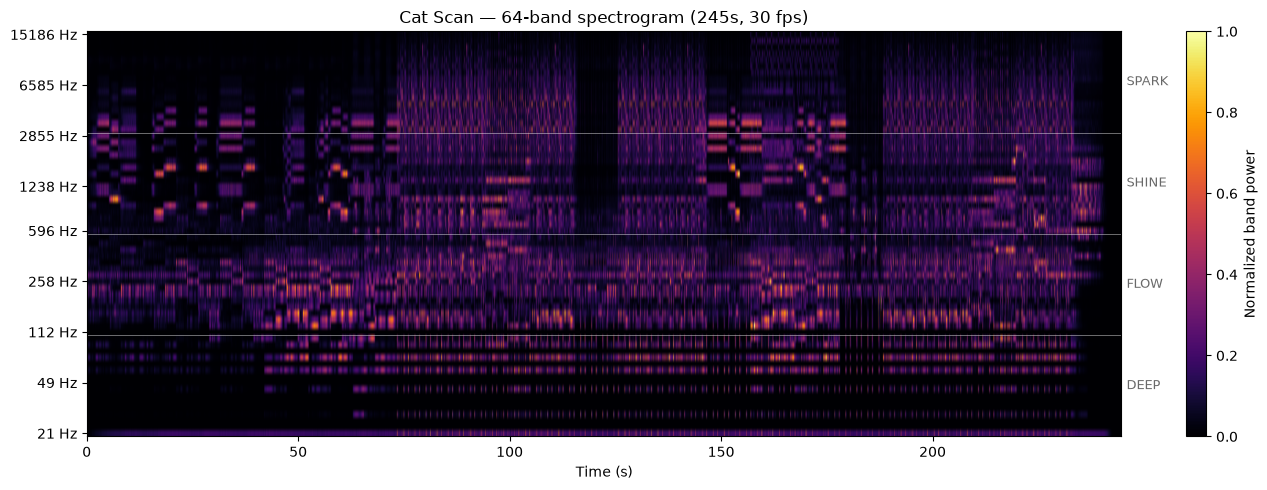

In [3]:
fig, ax = plt.subplots(figsize=(14, 5))
im = ax.imshow(tracks.T, aspect="auto", origin="lower", cmap="inferno",
               vmin=0, vmax=1, extent=[0, duration_s, 0, gen.N_BANDS])
plt.colorbar(im, ax=ax, label="Normalized band power")

for zi, z in enumerate(gen.ZONES):
    y = zi * gen.BANDS_PER_ZONE
    if zi:
        ax.axhline(y, color="white", linewidth=0.6, alpha=0.5)
    ax.text(duration_s * 1.005, y + gen.BANDS_PER_ZONE / 2, z.name,
            va="center", fontsize=9, color="dimgray")

ticks = np.round(np.linspace(0, gen.N_BANDS - 1, 9)).astype(int)
ax.set_yticks(ticks + 0.5)
ax.set_yticklabels([f"{band_freqs[i]:.0f} Hz" for i in ticks])
ax.set_xlabel("Time (s)")
ax.set_title(f"Cat Scan — {gen.N_BANDS}-band spectrogram ({duration_s:.0f}s, {gen.FPS:.0f} fps)")
plt.tight_layout()
plt.show()

## 3. Signal shaping: raw power vs. envelope

Raw FFT power strobes frame-to-frame. Each zone runs it through a peak-follower
(instant attack, exponential decay) with a zone-tuned time constant — DEEP booms
linger for half a second, SPARK snaps back in 120 ms. The envelope drives the scale
swell; raw power drives the spin/orbit rates (integration smooths those inherently).

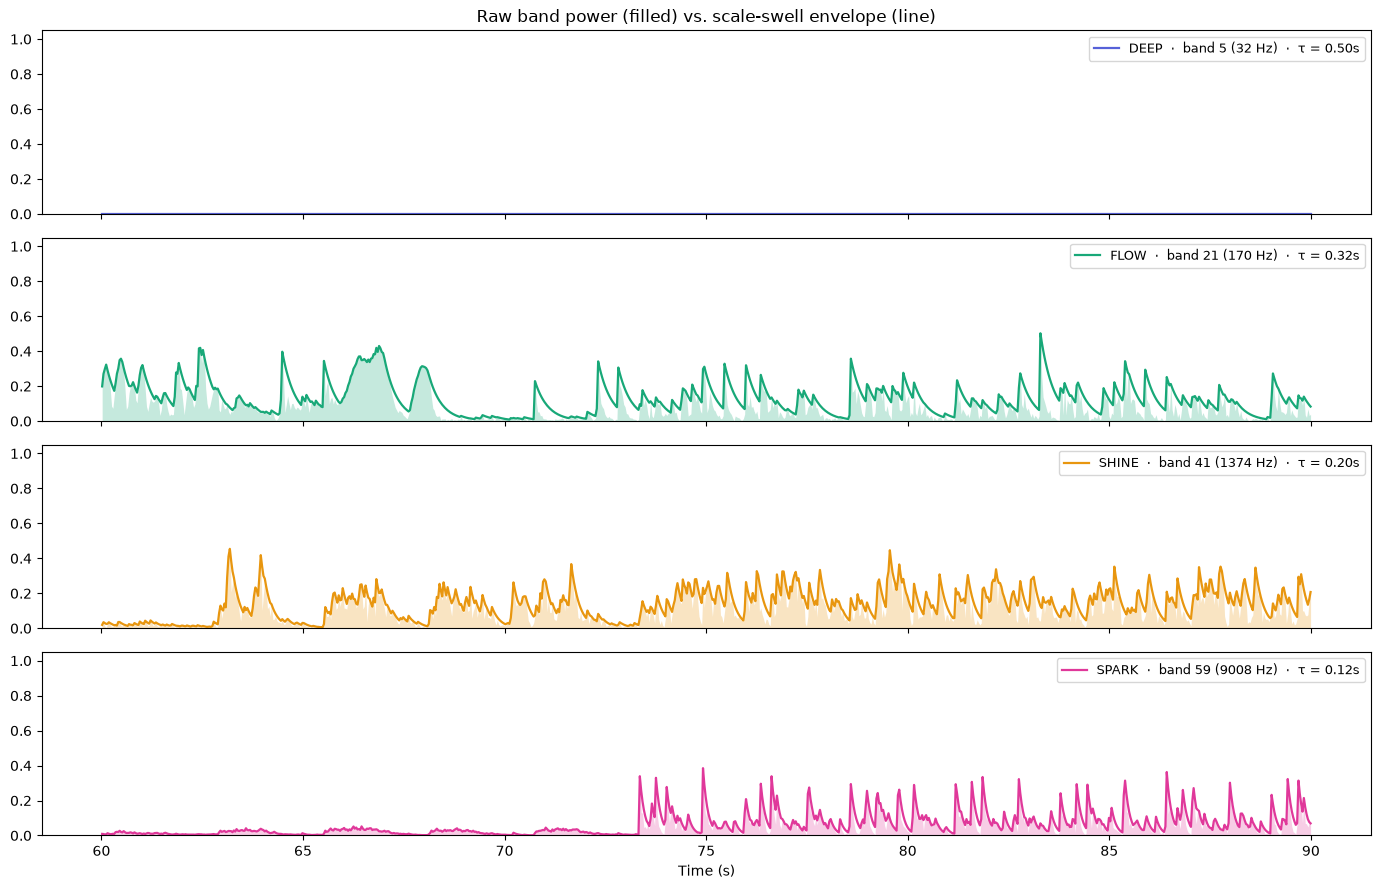

In [4]:
t0, t1 = 60.0, 90.0   # a 30-second excerpt
i0, i1 = int(t0 * gen.FPS), int(t1 * gen.FPS)
seg_t = time_axis[i0:i1]

fig, axes = plt.subplots(4, 1, figsize=(14, 9), sharex=True)
zone_band = [4, 20, 40, 58]   # a representative band inside each zone
zone_color = ["#5661d8", "#18a878", "#e8960f", "#e0389a"]

for ax, bi, color, z in zip(axes, zone_band, zone_color, gen.ZONES):
    p = tracks[:, bi]
    env = gen.envelope(p, gen.FPS, z.tau_scale)
    ax.fill_between(seg_t, p[i0:i1], color=color, alpha=0.25, linewidth=0)
    ax.plot(seg_t, env[i0:i1], color=color, linewidth=1.6,
            label=f"{z.name}  ·  band {bi + 1} ({band_freqs[bi]:.0f} Hz)  ·  τ = {z.tau_scale:.2f}s")
    ax.set_ylim(0, 1.05)
    ax.legend(loc="upper right", fontsize=9)

axes[0].set_title("Raw band power (filled) vs. scale-swell envelope (line)")
axes[-1].set_xlabel("Time (s)")
plt.tight_layout()
plt.show()

## 4. What each zone's motion looks like in numbers

Peak values of the four animated signals per zone (at full band power). Rates are
degrees per cycle at 60 cycles/s — SPARK's orbiters hit 144°/s, a full loop every 2.5 s.

In [5]:
print(f"{'zone':6s} {'objects':>7s} {'scale swell':>12s} {'alt pop':>8s} "
      f"{'spin °/s':>9s} {'orbit °/s':>10s} {'orbit axis':>12s}")
for z in gen.ZONES:
    n_obj = 1 + z.n2 + z.n2 * z.n3
    axis = "polar" if z.orbit_axis.endswith("_y") else "equatorial"
    print(f"{z.name:6s} {n_obj:7d} {z.scale_gain:+11.0%} {z.alt_peak:8.2f} "
          f"{z.spin_peak * 60:9.0f} {z.orbit_peak * 60:10.0f} {axis:>12s}")

total = 1 + sum(16 * (1 + z.n2 + z.n2 * z.n3) for z in gen.ZONES)
print(f"\nTotal scene: {total} nodes, {gen.CH_MASTER} channels, {gen.TRACK_MASTER} tracks")

zone   objects  scale swell  alt pop  spin °/s  orbit °/s   orbit axis
DEEP        55        +90%     0.70        36         18   equatorial
FLOW        64        +75%     0.85        72         42   equatorial
SHINE       73        +62%     1.00       132         78        polar
SPARK       91        +50%     1.20       210        144   equatorial

Total scene: 4529 nodes, 193 channels, 257 tracks


## 5. The palettes

Each band's three branch levels, all 64 bands: hue slides across each zone, the core (L1)
runs darker, the tips (L3) brighter and washed out — SPARK's branch-3 tetras go near-white.

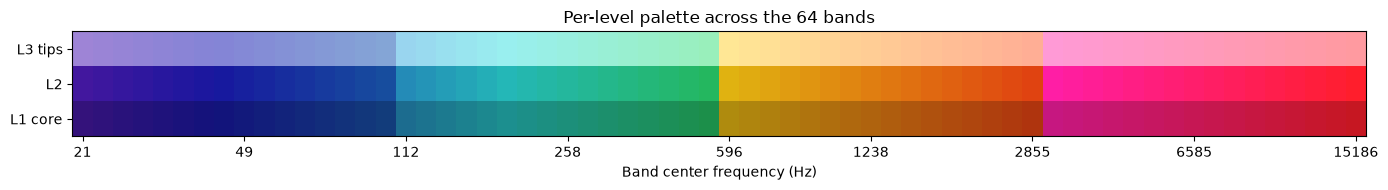

In [6]:
img = np.zeros((3, gen.N_BANDS, 3))
for i in range(gen.N_BANDS):
    c1, c2, c3 = gen.band_colors(i)
    img[0, i] = np.array(c3) / 255   # tips on top
    img[1, i] = np.array(c2) / 255
    img[2, i] = np.array(c1) / 255

fig, ax = plt.subplots(figsize=(14, 2))
ax.imshow(img, aspect="auto", extent=[0, gen.N_BANDS, 0, 3])
ax.set_yticks([0.5, 1.5, 2.5])
ax.set_yticklabels(["L1 core", "L2", "L3 tips"])
ticks = np.round(np.linspace(0, gen.N_BANDS - 1, 9)).astype(int)
ax.set_xticks(ticks + 0.5)
ax.set_xticklabels([f"{band_freqs[i]:.0f}" for i in ticks])
ax.set_xlabel("Band center frequency (Hz)")
ax.set_title("Per-level palette across the 64 bands")
plt.tight_layout()
plt.show()

## Done — things to try in GlyphViz

1. **File > Open Node CSV** → `Cat_Scan_Synesthesia_Example_gv_node.csv`, press **Play**.
2. **Change the master root's topology** (select node 1, Properties panel): Torus turns the
   sphere of bands into a ring, Cylinder into a column, Spiral into a helix — the whole
   instrument rearranges with one edit.
3. **Watch the SHINE zone** (gold octahedra): its branch-3 children orbit over the *poles*
   (`translate_rate_y`) instead of around the equator.
4. **Stop mid-song**: the rates reset to zero but the orbits stay wherever the music left
   them — the glyph remembers the song.
5. Re-run with any other WAV: `python generate_cat_scan_synesthesia.py --wav path/to.wav`
   (or change `gen.SOURCE_WAV` above and re-run the notebook).